# Instituto Tecnológico de Costa Rica
## Escuela de Computación • Curso de Inteligencia Artificial
### Proyecto Final: Clasificación Visual Multimodal con Deep Learning
---
**Estudiantes:** Joshua Picado & Carlos Arce  
**Profesor:** Ing. Efrén Jiménez Delgado  
**Semestre:** II Semestre, 2026  

**Objetivo del Cuaderno:**  
Implementar y comparar rigurosamente dos arquitecturas de *Transfer Learning* (**MobileNetV2** y **ResNet50**) sobre la misma partición controlada de datos (70% Train, 15% Val, 15% Test). Se evalúa precisión (*Accuracy*), matriz de confusión, reporte por clase ($P$, $R$, $F_1$) y latencia de inferencia en milisegundos ($ms$) para su posterior integración en video cuadro a cuadro ($\ge 5$ FPS).

## PASO 1: Conexión a Google Drive e Instalación de Dependencias

In [1]:
# 1. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Importar librerías principales
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print(f"\n[INFO] TensorFlow: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[INFO] Acelerador GPU activo: {gpus[0].name}")
else:
    print("[ADVERTENCIA] No se detectó GPU. Recuerde activar T4 GPU en Entorno de ejecución.")

Mounted at /content/drive

[INFO] TensorFlow: 2.21.0
[INFO] Acelerador GPU activo: /physical_device:GPU:0


## PASO 2: Configuración de Rutas en Google Drive y Carga del Dataset
El cuaderno busca la carpeta `IA/datasets/` en la raíz de su Google Drive.

In [3]:
# Identificar ruta de Google Drive (MyDrive o My Drive)
base_drive = '/content/drive/MyDrive' if os.path.exists('/content/drive/MyDrive') else '/content/drive/My Drive'
IA_DIR = os.path.join(base_drive, 'IA')
DATASETS_DIR = os.path.join(IA_DIR, 'Datasets')

print(f"Ruta base de Drive:     {IA_DIR}")
print(f"Ruta de los datasets:   {DATASETS_DIR}")

# Localizar carpeta descomprimida del dataset
candidate_paths = [
    os.path.join(DATASETS_DIR, 'vision_dataset'),
    os.path.join(DATASETS_DIR, 'gestos'),
    DATASETS_DIR
]

DATASET_PATH = None
for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'train')):
        DATASET_PATH = p
        break

# Si no está descomprimido pero existe el ZIP, descomprimirlo automáticamente
if DATASET_PATH is None:
    zip_path = os.path.join(DATASETS_DIR, 'dataset_gestos.zip')
    if os.path.exists(zip_path):
        print(f"[INFO] Descomprimiendo {zip_path}...")
        !unzip -q "{zip_path}" -d "{DATASETS_DIR}"
        DATASET_PATH = os.path.join(DATASETS_DIR, 'vision_dataset')
    else:
        raise FileNotFoundError(f"No se encontró la carpeta 'train' ni el archivo ZIP en {DATASETS_DIR}")

TRAIN_DIR = os.path.join(DATASET_PATH, 'train')
VAL_DIR = os.path.join(DATASET_PATH, 'val')
TEST_DIR = os.path.join(DATASET_PATH, 'test')

print(f"\n[ÉXITO] Dataset localizado en: {DATASET_PATH}")
print(f" - Train: {TRAIN_DIR}")
print(f" - Val:   {VAL_DIR}")
print(f" - Test:  {TEST_DIR}")

Ruta base de Drive:     /content/drive/MyDrive/IA
Ruta de los datasets:   /content/drive/MyDrive/IA/Datasets

[ÉXITO] Dataset localizado en: /content/drive/MyDrive/IA/Datasets/vision_dataset
 - Train: /content/drive/MyDrive/IA/Datasets/vision_dataset/train
 - Val:   /content/drive/MyDrive/IA/Datasets/vision_dataset/val
 - Test:  /content/drive/MyDrive/IA/Datasets/vision_dataset/test


## PASO 3: Creación de Pipelines de Datos (Train, Val, Test)
Se asegura una resolución uniforme de $224 \times 224$ píxeles y se preserva la partición estricta **70% / 15% / 15%** sin fuga de información.

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"\nClases identificadas ({num_classes}): {class_names}")

# Guardar archivo de clases para el backend
classes_file = os.path.join(IA_DIR, 'classes.txt')
with open(classes_file, 'w', encoding='utf-8') as f:
    for c in class_names:
        f.write(f"{c}\n")
print(f"Archivo classes.txt guardado en: {classes_file}")

Found 140 files belonging to 2 classes.
Found 30 files belonging to 2 classes.
Found 30 files belonging to 2 classes.

Clases identificadas (2): ['palma_abierta', 'puno_cerrado']
Archivo classes.txt guardado en: /content/drive/MyDrive/IA/classes.txt


## PASO 4: Visualización de Muestras y Capas de Aumento de Datos (*Data Augmentation*)
El aumento de datos se aplica exclusivamente durante el entrenamiento para dotar al modelo de invariancia ante rotaciones, traslaciones y variaciones lumínicas del entorno real.

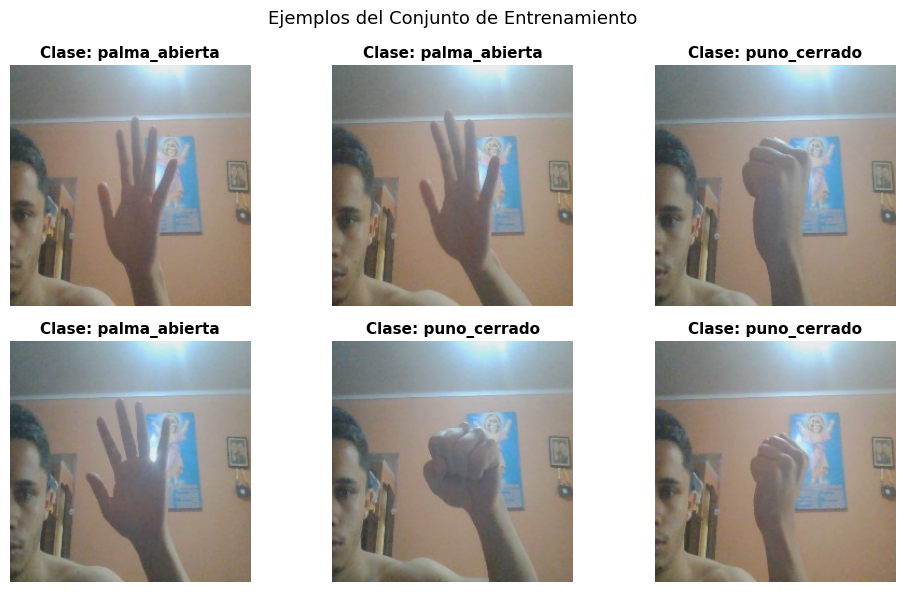

In [5]:
# Visualizar 6 ejemplos del conjunto de entrenamiento
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(min(6, len(images))):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Clase: {class_names[labels[i]]}", fontsize=11, fontweight='bold')
        plt.axis("off")
plt.suptitle("Ejemplos del Conjunto de Entrenamiento", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

# Definición de aumento de datos
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.12),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.10)
], name="data_augmentation")

## PASO 5: MODELO 1 — MobileNetV2 (Arquitectura Ligera para Tiempo Real)
Optimizada con convoluciones separables en profundidad. Ideal para garantizar $\ge 5$ FPS en inferencia de video continuo.

In [6]:
# Base MobileNetV2 preentrenada en ImageNet
base_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_mobilenet.trainable = False  # Congelamiento inicial de pesos

# Topología de clasificación
inputs = layers.Input(shape=(224, 224, 3), name="input_image")
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_mobilenet(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.35, name="dropout_1")(x)
x = layers.Dense(128, activation="relu", name="dense_128")(x)
x = layers.Dropout(0.20, name="dropout_2")(x)
outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)

model_mobilenet = keras.Model(inputs, outputs, name="MobileNetV2_Transfer")
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mobilenet.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
EPOCHS = 18
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)
]

print("\nIniciando entrenamiento de MobileNetV2...")
history_mobilenet = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Iniciando entrenamiento de MobileNetV2...
Epoch 1/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 74s 7s/step - accuracy: 0.5786 - loss: 1.0992 - val_accuracy: 1.0000 - val_loss: 0.2063 - learning_rate: 0.0010
Epoch 2/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8643 - loss: 0.2736 - val_accuracy: 0.8333 - val_loss: 0.3522 - learning_rate: 0.0010
Epoch 3/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9071 - loss: 0.2240 - val_accuracy: 1.0000 - val_loss: 0.0712 - learning_rate: 0.0010
Epoch 4/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.9429 - loss: 0.1519 - val_accuracy: 1.0000 - val_loss: 0.0555 - learning_rate: 0.0010
Epoch 5/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9571 - loss: 0.1111 - val_accuracy: 1.0000 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 6/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.9786 - loss: 0.0584 - val_accuracy: 1.0000 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 7/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9

## PASO 6: MODELO 2 — ResNet50 (Arquitectura Convolucional Residual Profunda)
Emplea conexiones de salto residual (*skip connections*) para aprender representaciones complejas. Sirve de contraparte comparativa frente a MobileNetV2.

In [8]:
# Base ResNet50 preentrenada en ImageNet
base_resnet = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_resnet.trainable = False  # Congelamiento inicial de pesos

# Topología de clasificación
inputs_r = layers.Input(shape=(224, 224, 3), name="input_image_resnet")
x_r = data_augmentation(inputs_r)
x_r = tf.keras.applications.resnet50.preprocess_input(x_r)
x_r = base_resnet(x_r, training=False)
x_r = layers.GlobalAveragePooling2D(name="gap_resnet")(x_r)
x_r = layers.Dense(256, activation="relu", name="dense_256")(x_r)
x_r = layers.Dropout(0.40, name="dropout_resnet")(x_r)
outputs_r = layers.Dense(num_classes, activation="softmax", name="predictions_resnet")(x_r)

model_resnet = keras.Model(inputs_r, outputs_r, name="ResNet50_Transfer")
model_resnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_resnet.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "ResNet50_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image_resnet  │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_image_resn… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gap_resnet          │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_256 (Dense)   │ (None, 256)       │    524,544 │ gap_resnet[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_resnet      │ (None, 256)       │          0 │ dense_256[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions_resnet  │ (None, 2)         │        514 │ dropout_resnet[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,112,770 (91.98 MB)

 Trainable params: 525,058 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [9]:
print("\nIniciando entrenamiento de ResNet50...")
history_resnet = model_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


Iniciando entrenamiento de ResNet50...
Epoch 1/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 16s 865ms/step - accuracy: 0.5571 - loss: 2.1446 - val_accuracy: 0.7333 - val_loss: 0.3846 - learning_rate: 0.0010
Epoch 2/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7339 - loss: 0.6356
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.8214 - loss: 0.4577 - val_accuracy: 0.9667 - val_loss: 0.1018 - learning_rate: 0.0010
Epoch 3/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9643 - loss: 0.1165 - val_accuracy: 1.0000 - val_loss: 0.0376 - learning_rate: 5.0000e-04
Epoch 4/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9401 - loss: 0.1285
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9500 - loss: 0.1059 - val_accuracy: 1.0000 - val_loss: 0.0271 - learning_rate: 5.0000e-04
Epoch 5/18
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accurac

## PASO 7: Comparación de Curvas de Aprendizaje (Pérdida y Precisión)
Estas gráficas se incluyen directamente en la sección de Resultados del Paper técnico IEEE.

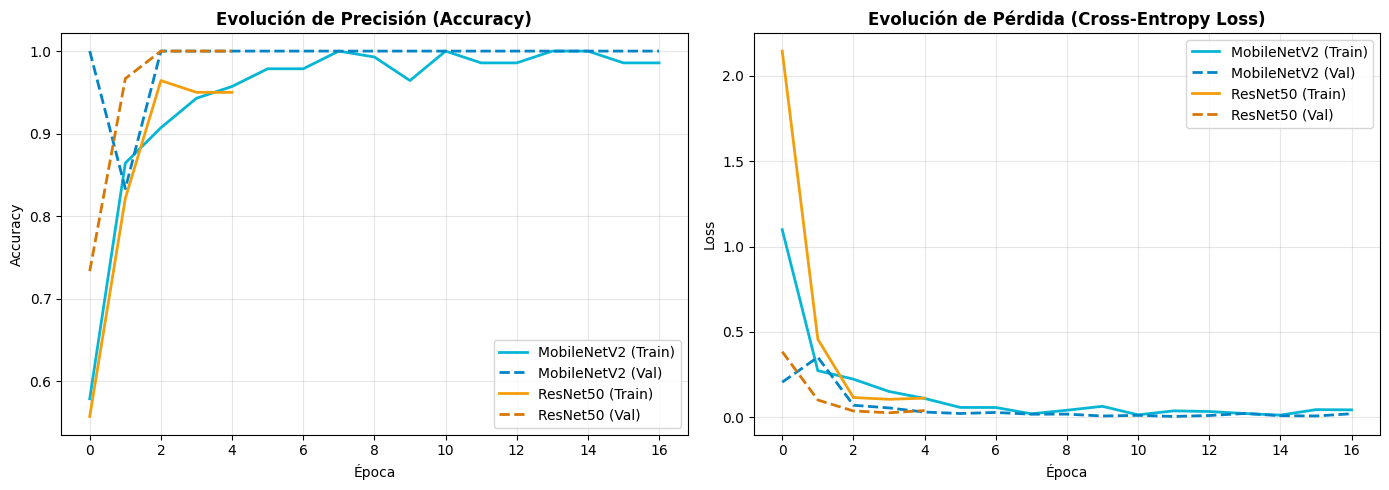

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica de Accuracy
axes[0].plot(history_mobilenet.history['accuracy'], label='MobileNetV2 (Train)', color='#06b6d4', lw=2)
axes[0].plot(history_mobilenet.history['val_accuracy'], label='MobileNetV2 (Val)', color='#0284c7', ls='--', lw=2)
axes[0].plot(history_resnet.history['accuracy'], label='ResNet50 (Train)', color='#f59e0b', lw=2)
axes[0].plot(history_resnet.history['val_accuracy'], label='ResNet50 (Val)', color='#d97706', ls='--', lw=2)
axes[0].set_title("Evolución de Precisión (Accuracy)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Gráfica de Loss
axes[1].plot(history_mobilenet.history['loss'], label='MobileNetV2 (Train)', color='#06b6d4', lw=2)
axes[1].plot(history_mobilenet.history['val_loss'], label='MobileNetV2 (Val)', color='#0284c7', ls='--', lw=2)
axes[1].plot(history_resnet.history['loss'], label='ResNet50 (Train)', color='#f59e0b', lw=2)
axes[1].plot(history_resnet.history['val_loss'], label='ResNet50 (Val)', color='#d97706', ls='--', lw=2)
axes[1].set_title("Evolución de Pérdida (Cross-Entropy Loss)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(IA_DIR, 'curvas_comparacion.png'), dpi=300)
plt.show()

## PASO 8: Evaluación Rigurosa en el Conjunto de Test (15% No Visto)
Se evalúan las métricas formales exigidas por la rúbrica del curso:
1. Reporte de Clasificación por Clase (Precisión, Recall, F1-Score).
2. Matriz de Confusión normalizada.
3. Medición del **tiempo de inferencia en milisegundos (ms)** y cálculo de FPS teóricos.


  EVALUACIÓN TEST: MobileNetV2
Tiempo promedio de inferencia: 106.33 ms por imagen
Velocidad estimada:            9.4 FPS (Mínimo requerido: 5 FPS)

Reporte de Clasificación:
               precision    recall  f1-score   support

palma_abierta     1.0000    1.0000    1.0000        15
 puno_cerrado     1.0000    1.0000    1.0000        15

     accuracy                         1.0000        30
    macro avg     1.0000    1.0000    1.0000        30
 weighted avg     1.0000    1.0000    1.0000        30


  EVALUACIÓN TEST: ResNet50
Tiempo promedio de inferencia: 88.80 ms por imagen
Velocidad estimada:            11.3 FPS (Mínimo requerido: 5 FPS)

Reporte de Clasificación:
               precision    recall  f1-score   support

palma_abierta     0.6250    1.0000    0.7692        15
 puno_cerrado     1.0000    0.4000    0.5714        15

     accuracy                         0.7000        30
    macro avg     0.8125    0.7000    0.6703        30
 weighted avg     0.8125    0.7000    0.6

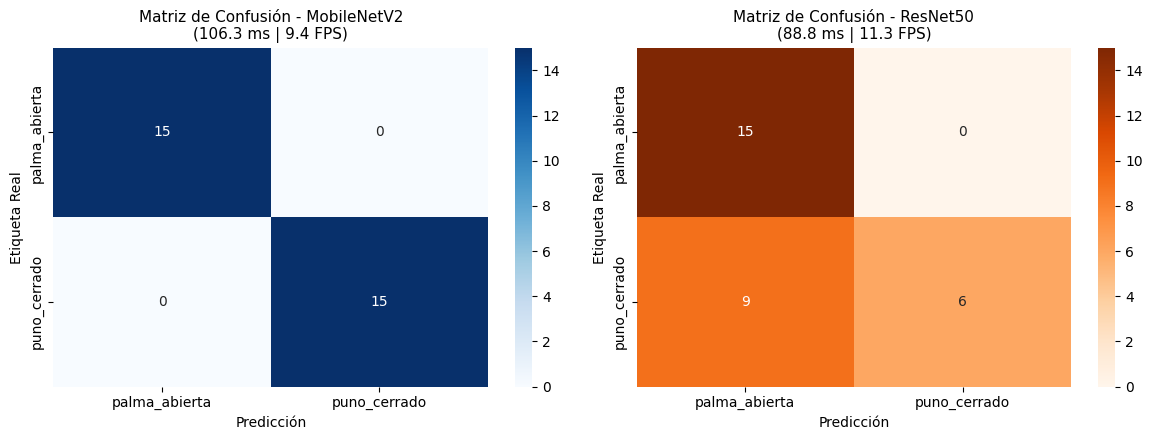

In [11]:
def evaluate_complete(model, test_dataset, model_name):
    y_true = []
    y_pred = []
    latencies = []

    for images, labels in test_dataset:
        for i in range(len(images)):
            img = tf.expand_dims(images[i], axis=0)
            t0 = time.perf_counter()
            pred = model.predict(img, verbose=0)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) * 1000)
            y_true.append(int(labels[i]))
            y_pred.append(int(np.argmax(pred)))

    # Descartar las primeras 5 muestras para estabilizar el calentamiento (warmup) de GPU
    stable_latencies = latencies[5:] if len(latencies) > 5 else latencies
    avg_latency = np.mean(stable_latencies)
    fps = 1000.0 / avg_latency if avg_latency > 0 else 0

    print(f"\n{'='*55}")
    print(f"  EVALUACIÓN TEST: {model_name}")
    print(f"{'='*55}")
    print(f"Tiempo promedio de inferencia: {avg_latency:.2f} ms por imagen")
    print(f"Velocidad estimada:            {fps:.1f} FPS (Mínimo requerido: 5 FPS)")
    print("\nReporte de Clasificación:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    return y_true, y_pred, cm, avg_latency, fps

yt_m, yp_m, cm_m, lat_m, fps_m = evaluate_complete(model_mobilenet, test_ds, "MobileNetV2")
yt_r, yp_r, cm_r, lat_r, fps_r = evaluate_complete(model_resnet, test_ds, "ResNet50")

# Graficar matrices de confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm_m, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f"Matriz de Confusión - MobileNetV2\n({lat_m:.1f} ms | {fps_m:.1f} FPS)", fontsize=11)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Etiqueta Real")

sns.heatmap(cm_r, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title(f"Matriz de Confusión - ResNet50\n({lat_r:.1f} ms | {fps_r:.1f} FPS)", fontsize=11)
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.savefig(os.path.join(IA_DIR, 'matrices_confusion.png'), dpi=300)
plt.show()

## PASO 9: Exportación de Modelos Entrenados (.keras)
Se guardan directamente en su carpeta de Google Drive `IA/` para su descarga e integración inmediata en la aplicación web (`10N-AI`).

In [12]:
# Guardar en Google Drive
mobilenet_out = os.path.join(IA_DIR, 'vision_mobilenet.keras')
resnet_out = os.path.join(IA_DIR, 'vision_resnet.keras')

model_mobilenet.save(mobilenet_out)
model_resnet.save(resnet_out)

print("\n[ÉXITO] Modelos guardados directamente en su Google Drive:")
print(f" 1. {mobilenet_out}")
print(f" 2. {resnet_out}")
print("\n¡Descárguelos o cópielos a 'backend/models_dl/' para la demostración en vivo!")


[ÉXITO] Modelos guardados directamente en su Google Drive:
 1. /content/drive/MyDrive/IA/vision_mobilenet.keras
 2. /content/drive/MyDrive/IA/vision_resnet.keras

¡Descárguelos o cópielos a 'backend/models_dl/' para la demostración en vivo!
